In [1]:
import os
import numpy as np

SEQ  = "RECORD@2020-11-22_12.54.38"
DATA = rf"C:\Users\daksh\Documents\SPARSE_FFT\data\{SEQ}\{SEQ}"

log_path = os.path.join(DATA, SEQ + "_events_log.rec")
print(os.path.exists(log_path))

True


In [3]:
radar = {"radar_ch0": {}, "radar_ch1": {}, "radar_ch2": {}, "radar_ch3": {}}

with open(log_path) as f:
    for line in f:
        pieces = line.split()
        if len(pieces) != 17:
            continue
        sensor = pieces[10]
        if sensor not in radar:
            continue
        sample   = int(pieces[7])
        offset   = int(pieces[13])
        datasize = int(pieces[16])
        radar[sensor][sample] = (offset, datasize)

for name in radar:
    print(name, len(radar[name]))

radar_ch0 463
radar_ch1 459
radar_ch2 462
radar_ch3 462


In [5]:
frames = []                                  # list of ch3 sample numbers that have all 4 chips

for n in radar["radar_ch3"]:
    if (n + 1) in radar["radar_ch0"] and (n + 2) in radar['radar_ch2']   and (n + 3) in radar['radar_ch1']:
        frames.append(n)

print(len(frames), frames[0], frames[-1])

452 13457 15300


In [7]:
def read_block(chip, offset, datasize):
    path = os.path.join(DATA, SEQ + f"_{chip}.bin")
    with open(path, "rb") as f:
        f.seek(offset)
        x = np.fromfile(f, dtype=np.int16, count=datasize//2)
    return x

def chip_cube(x):
    c = x[0::2] + 1j * x[1::2]
    c = np.reshape(c, (512, 4, 256), order="F")
    return c.transpose((0, 2, 1))


n = frames[0]
off3, size3 = radar["radar_ch3"][n]
off0, size0 = radar["radar_ch0"][n + 1]
off2, size2 = radar["radar_ch2"][n + 2]
off1, size1 = radar["radar_ch1"][n + 3]

c3 = chip_cube(read_block("radar_ch3", off3, size3))
c0 = chip_cube(read_block("radar_ch0", off0, size0))
c2 = chip_cube(read_block("radar_ch2", off2, size2))
c1 = chip_cube(read_block("radar_ch1", off1, size1))

cube = np.concatenate([c3, c0, c1, c2], axis=2)
print(cube.shape, cube.dtype)

(512, 256, 16) complex128


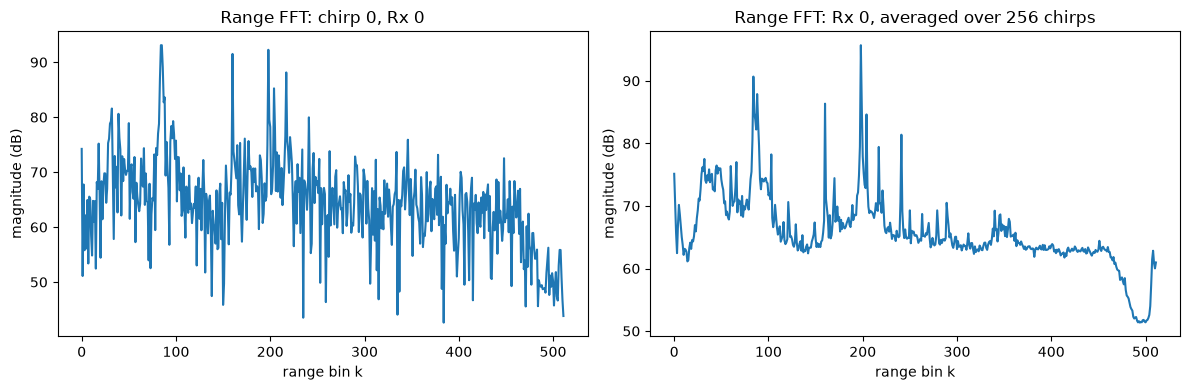

In [ ]:
import matplotlib.pyplot as plt

# 1) one chirp, one antenna
x = cube[:, 0, 0]              # all 512 samples, chirp 0, Rx 0
X = np.fft.fft(x)
mag_db = 20 * np.log10(np.abs(X) + 1e-9)

# 2) all chirps for Rx 0, then average over chirps
R = np.fft.fft(cube[:, :, 0], axis= 0)       # FFT along the sample axis
avg_db = 20 * np.log10(np.abs(R).mean(axis=1) + 1e-9)   # average over chirps

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(mag_db)
ax[0].set_title("Range FFT: chirp 0, Rx 0")
ax[1].plot(avg_db)
ax[1].set_title("Range FFT: Rx 0, averaged over 256 chirps")
for a in ax:
    a.set_xlabel("range bin k")
    a.set_ylabel("magnitude (dB)")  
plt.tight_layout()
plt.savefig(r"C:\Users\daksh\Documents\SPARSE_FFT\figures\range_fft_frame0.png", dpi=140)
plt.show()

(512, 256, 16)


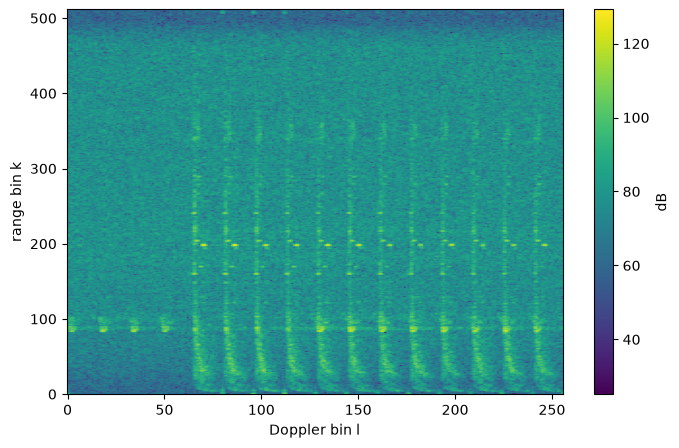

In [ ]:
# 1) DC removal: one mean per Rx antenna
cube_dc = cube - cube.mean(axis=(0, 1), keepdims=True)     # mean over samples and chirps

# 2) Hamming windows
N, M = 512, 256
w_range   = 0.54 - 0.46 * np.cos(2 * np.pi * np.arange(N) / (N - 1))
w_doppler = 0.54 - 0.46 * np.cos(2 * np.pi * np.arange(M) / (M - 1))

# 3) range window + range FFT, then Doppler window + Doppler FFT
rng = np.fft.fft(cube_dc * w_range[:, None, None], axis=0)
rd  = np.fft.fft(rng * w_doppler[None, :, None], axis=1)
print(rd.shape)

# 4) range-Doppler map for Rx 0
rd_db = 20 * np.log10(np.abs(rd[:, :, 0]) + 1e-9)
plt.figure(figsize=(8, 5))
plt.imshow(rd_db, aspect="auto", origin="lower")
plt.colorbar(label="dB")
plt.xlabel("Doppler bin l"); plt.ylabel("range bin k")
plt.savefig(r"C:\Users\daksh\Documents\SPARSE_FFT\figures\rd_map_frame0.png", dpi=140)
plt.show()  

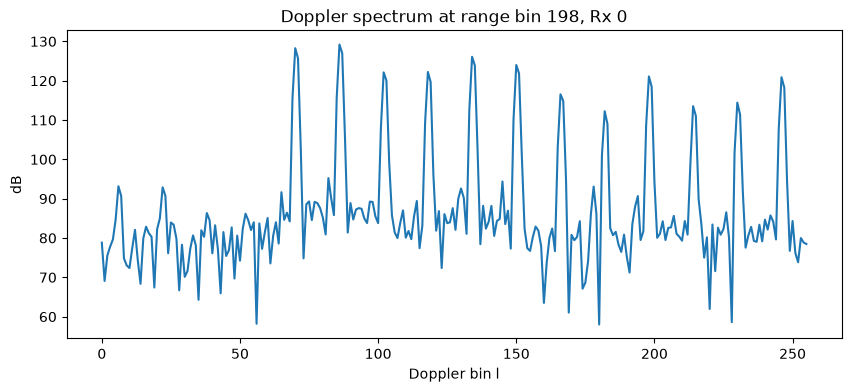

[ 70  71  86  87 102 118 134 135 150 151 198 246]
[ 1 15  1 15 16 16  1 15  1 47 48]


In [12]:
k = 198                                    # the range bin to look at
row = rd_db[k, :]                      # all 256 Doppler bins at range bin k, Rx 0 (rd_db is already (512, 256))

plt.figure(figsize=(10, 4))
plt.plot(row)
plt.xlabel("Doppler bin l"); plt.ylabel("dB")
plt.title(f"Doppler spectrum at range bin {k}, Rx 0")
plt.savefig(r"C:\Users\daksh\Documents\SPARSE_FFT\figures\doppler_row_198.png", dpi=140)
plt.show()

top12 = np.sort(np.argsort(row)[-12:])      # indices of the 12 largest values, sorted
print(top12)
print(np.diff(top12))                      # gaps between neighbouring peaks

In [13]:
from scipy.signal import find_peaks

peaks, _ = find_peaks(row, distance=2)         # min spacing between peaks, in bins
top = np.sort(peaks[np.argsort(row[peaks])[-12:]])   # keep the 12 highest peaks, sorted
print(top)
print(np.diff(top))

[ 70  86 102 118 134 150 166 182 198 214 230 246]
[16 16 16 16 16 16 16 16 16 16 16]


In [14]:
Pm = np.sum(np.abs(rd), axis=2)               # (512, 256), sum of magnitudes over the 16 Rx
P_red = Pm.reshape(512, 16, 16).sum(axis=1)    # (512, 16), the folded map

k = 198
b = np.argmax(P_red[k])                                         # folded bin of the strongest peak in row k of P_red
slots = Pm[k, b::16]                             # 16 slot values for this target
ext = np.concatenate([slots, slots[:4]])         # wrap around
cs  = np.cumsum(ext)
win = (cs[4:] - cs[:-4]) / 4                     # mean of slots j+1 ... j+4
j = np.argmin(win)
tx0_bin = 16 * j + b                                   # 16*j + b
print(b, j, tx0_bin)

6 15 246


In [15]:
from scipy.signal import convolve2d

def ca_cfar(P, n_rng=9, n_dop=9, g_rng=3, g_dop=3, thr_db=2):
    pw = np.abs(P) ** 2                              # power, shape (512, 16)
    mask = np.ones((2*n_rng + 1, 2*n_dop + 1))       # 19 x 19, all ones
    mask[n_rng-g_rng : n_rng+g_rng+1, n_dop-g_dop : n_dop+g_dop+1] = 0   # guard block and CUT are not training

    sums   = convolve2d(pw, mask, mode="same")                    # sum of training cells at every cell
    counts = convolve2d(np.ones_like(pw), mask, mode="same")      # how many training cells really exist
    noise  = sums/counts                                                  # average noise power per cell
    snr    = pw / noise
    return snr > 10 ** (thr_db / 10)

hits = ca_cfar(P_red)
det = np.argwhere(hits)              # list of (range bin, folded Doppler bin)
print(hits.sum(), det[:10])

593 [[ 0  0]
 [ 0  1]
 [ 0 15]
 [ 1  0]
 [ 1  1]
 [ 1 15]
 [ 2  0]
 [ 2  1]
 [ 2 15]
 [ 3  0]]


2 593
4 349
6 213


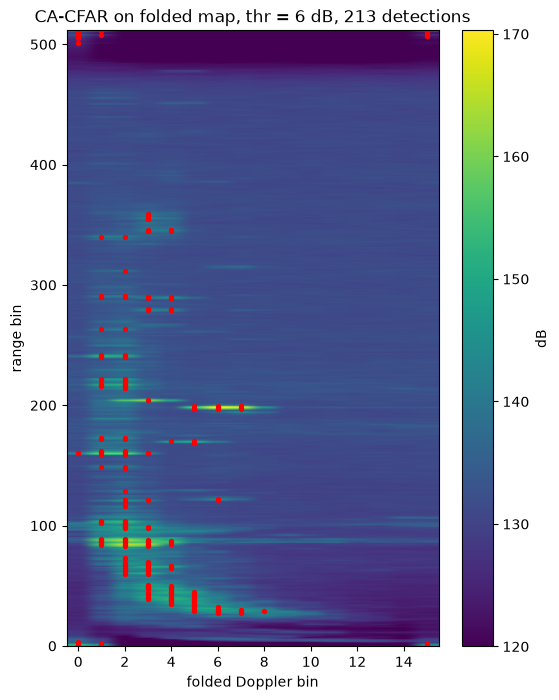

In [22]:
for t in (2, 4, 6):
    h = ca_cfar(P_red, thr_db=t)
    print(t, h.sum())

hits = ca_cfar(P_red, thr_db=6)
det = np.argwhere(hits)

os.makedirs("../figures", exist_ok=True)       # repo-level figures folder (notebook is in notebooks\)

plt.figure(figsize=(6, 8))
im = plt.imshow(20*np.log10(P_red + 1e-9), aspect="auto", origin="lower", vmin=120)
plt.scatter(det[:, 1], det[:, 0], s=8, c="r")     # x = Doppler column, y = range bin
plt.xlabel("folded Doppler bin"); plt.ylabel("range bin")
plt.colorbar(im, label="dB")
plt.title(f"CA-CFAR on folded map, thr = 6 dB, {hits.sum()} detections")
plt.savefig("../figures/cfar_folded_thr6.png", dpi=150, bbox_inches="tight")   # must come before show()
plt.show()

In [23]:
import pandas as pd

labels = pd.read_csv("../data/labels_CVPR.csv")
lab = labels[labels["dataset"] == "RECORD@2020-11-22_12.54.38"]

M_PER_BIN = (103/512)                                  # metres per range bin
lab = lab.assign(range_bin = lab["radar_R_m"] / M_PER_BIN)

f0 = lab[lab["index"] == 0]                    # the first frame
print(f0[["radar_R_m", "range_bin", "radar_A_deg", "radar_D_mps", "Annotation"]])

      radar_R_m  range_bin  radar_A_deg  radar_D_mps Annotation
3219  18.364132  91.285782         19.6         52.0     strong


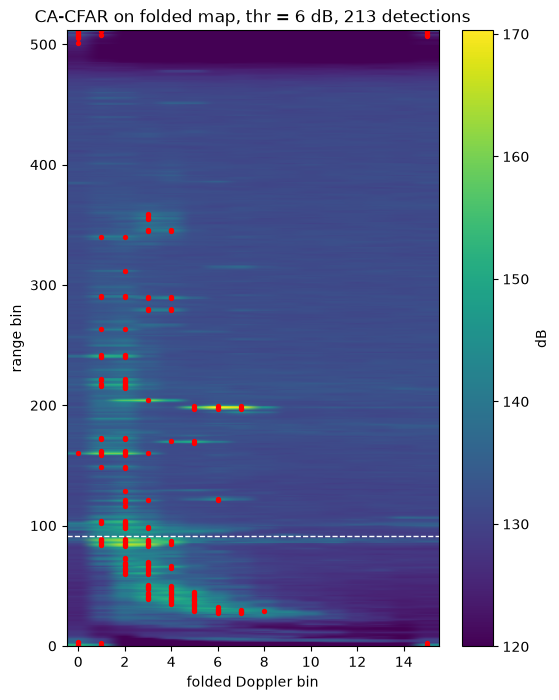

In [24]:
os.makedirs("../figures", exist_ok=True)

plt.figure(figsize=(6, 8))
im = plt.imshow(20*np.log10(P_red + 1e-9), aspect="auto", origin="lower", vmin=120)
plt.scatter(det[:, 1], det[:, 0], s=8, c="r")

for rb in f0["range_bin"]:                       # one line per labelled vehicle in frame 0
    plt.axhline(rb, color="w", ls="--", lw=1)

plt.xlabel("folded Doppler bin"); plt.ylabel("range bin")
plt.colorbar(im, label="dB")
plt.title(f"CA-CFAR on folded map, thr = 6 dB, {hits.sum()} detections")
plt.savefig("../figures/cfar_folded_thr6_label.png", dpi=150, bbox_inches="tight")
plt.show()

In [47]:
def frame_to_pred(n, mti=False):
    keys = [("radar_ch3", n), ("radar_ch0", n+1), ("radar_ch1", n+3), ("radar_ch2", n+2)]

    cubes = []
    for chip, s in keys:
        off, size = radar[chip][s]
        cubes.append(chip_cube(read_block(chip, off, size)))   # each is (512, 256, 4)

    cube = np.concatenate(cubes, axis=2)                     # -> (512, 256, 16)
    if mti:
        cube = cube - cube.mean(axis=1, keepdims=True)       # mean over the 256 chirps, per range bin and channel
    else:
        cube = cube - cube.mean(axis=(0, 1), keepdims=True)  # DC offset per channel

    rng = np.fft.fft(cube * w_range[:, None, None],   axis=0)
    rd  = np.fft.fft(rng  * w_doppler[None, :, None], axis=1)

    Pm = np.sum(np.abs(rd), axis=2)                          # sum over the 16 channels
    return Pm.reshape(512, 16, 16).sum(axis=1)            # the fold

In [29]:
P0 = frame_to_pred(frames[0])
print(np.allclose(P0, P_red))        # must print True
P22 = frame_to_pred(frames[22])
print(P22.shape)                     # (512, 16)

True
(512, 16)


      radar_R_m   range_bin  radar_A_deg Annotation
3221  36.728264  182.571564          5.9     strong


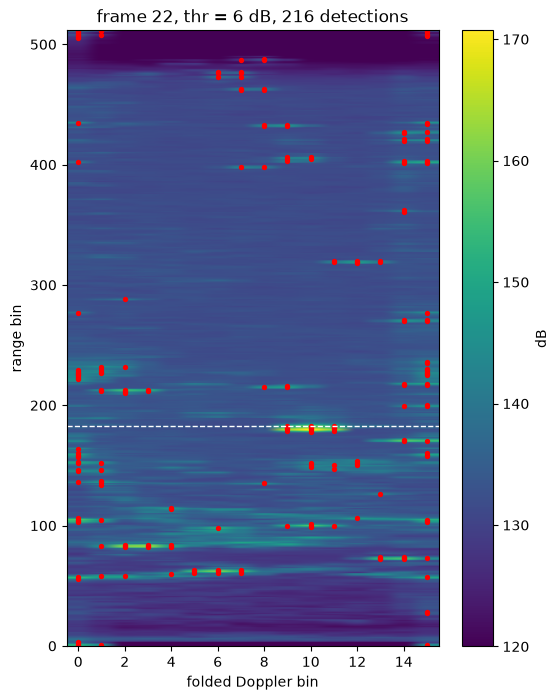

In [30]:
P22  = frame_to_pred(frames[22])
hits = ca_cfar(P22, thr_db=6)
det  = np.argwhere(hits)

f22 = lab[lab["index"] == 22]
print(f22[["radar_R_m", "range_bin", "radar_A_deg", "Annotation"]])

plt.figure(figsize=(6, 8))
im = plt.imshow(20*np.log10(P22 + 1e-9), aspect="auto", origin="lower", vmin=120)
plt.scatter(det[:, 1], det[:, 0], s=8, c="r")
for rb in f22["range_bin"]:
    plt.axhline(rb, color="w", ls="--", lw=1)
plt.xlabel("folded Doppler bin"); plt.ylabel("range bin")
plt.colorbar(im, label="dB")
plt.title(f"frame 22, thr = 6 dB, {hits.sum()} detections")
plt.savefig("../figures/cfar_frame22_label.png", dpi=150, bbox_inches="tight")
plt.show()

In [49]:
print(ca_cfar(frame_to_pred(frames[22]), thr_db=4).sum(),
      ca_cfar(frame_to_pred(frames[22], mti=True), thr_db=4).sum())

357 354


In [31]:
def match_frame(k, thr_db=6, gate=5):
    P = frame_to_pred(frames[k])
    hits = ca_cfar(P, thr_db=thr_db)
    det_rng = np.unique(np.argwhere(hits)[:, 0])       # range bins that have at least one detection
    labs = lab[lab["index"] == k]["range_bin"].values    # label range bins in this frame

    out = []
    for rb in labs:
        found = np.any(np.abs(det_rng - rb) <= gate)
        out.append(found)
    return out

print(match_frame(0))
print(match_frame(22))

[np.True_]
[np.True_]


In [34]:
ks = sorted(lab["index"].unique())[:30]
rng_ = np.random.default_rng(0)
real, fake = [], []

for k in ks:
    P = frame_to_pred(frames[k])
    det_rng = np.unique(np.argwhere(ca_cfar(P, thr_db=6))[:, 0])

    labs = lab[lab["index"] == k]["range_bin"].values

    for rb in labs:
        real.append(np.any(np.abs(det_rng - rb) <= 5))

        fake_rb = rng_.uniform(5, 500)
        while np.any(np.abs(labs - fake_rb) <= 10):
            fake_rb = rng_.uniform(5, 500)
        fake.append(np.any(np.abs(det_rng - fake_rb) <= 5))

print(len(real), len(fake), np.mean(real), np.mean(fake))

37 37 0.9459459459459459 0.5675675675675675


In [35]:
ks = sorted(lab["index"].unique())              # all labelled frames
real, c_k, n_k = [], [], []
bins = np.arange(5, 500)

for k in ks:
    P = frame_to_pred(frames[k])
    det_rng = np.unique(np.argwhere(ca_cfar(P, thr_db=6))[:, 0])
    labs = lab[lab["index"] == k]["range_bin"].values

    for rb in labs:
        real.append(np.any(np.abs(det_rng - rb) <= 5))

    free = bins[np.all(np.abs(bins[:, None] - labs[None, :]) > 10, axis=1)]    # bins not near a real vehicle
    if len(det_rng) > 0:
        dist = np.min(np.abs(free[:, None] - det_rng[None, :]), axis=1)         # distance to the nearest detection
        c_k.append(np.mean(dist <= 5))
    else:
        c_k.append(0.0)
    n_k.append(len(labs))

h = np.mean(real)
c = np.average(c_k, weights=n_k)
print(len(real), h, c, (h - c) / (1 - c))

556 0.89568345323741 0.5399221983979758 0.7732632472174223


In [36]:
ks = sorted(lab["index"].unique())
P_all = {k: frame_to_pred(frames[k]) for k in ks}      # ~26 MB in memory

In [37]:
def evaluate(thr_db, gate=5):
    real, c_k, n_k = [], [], []
    bins = np.arange(5, 500)

    for k in ks:
        P = P_all[k]
        det_rng = np.unique(np.argwhere(ca_cfar(P, thr_db=thr_db))[:, 0])
        labs = lab[lab["index"] == k]["range_bin"].values

        for rb in labs:
            real.append(np.any(np.abs(det_rng - rb) <= gate))

        free = bins[np.all(np.abs(bins[:, None] - labs[None, :]) > 10, axis=1)]
        if len(det_rng) > 0:
            dist = np.min(np.abs(free[:, None] - det_rng[None, :]), axis=1)
            c_k.append(np.mean(dist <= gate))
        else:
            c_k.append(0.0)
        n_k.append(len(labs))

    h = np.mean(real)
    c = np.average(c_k, weights=n_k)
    return h, c, (h - c) / (1 - c)

for t in (2, 4, 6, 8, 10):
    print(t, evaluate(t))

2 (np.float64(0.9784172661870504), np.float64(0.8900902824465465), np.float64(0.803632160164063))
4 (np.float64(0.9514388489208633), np.float64(0.7103769230800393), np.float64(0.8323298281491673))
6 (np.float64(0.89568345323741), np.float64(0.5399221983979758), np.float64(0.7732632472174223))
8 (np.float64(0.8651079136690647), np.float64(0.3905829336944519), np.float64(0.7786539074977211))
10 (np.float64(0.814748201438849), np.float64(0.28504096640900084), np.float64(0.7408917296552036))


3 131


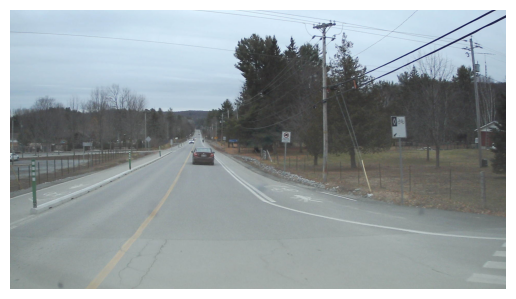

In [44]:
import cv2

cam_ts, cam_tio, cam_off, cam_size = [], [], [], []
ch3_ts, ch3_tio = {}, {}

with open(log_path) as f:
    for line in f:
        p = line.split()
        if len(p) != 17: continue
        if p[10] == "camera":
            cam_ts.append(int(p[1]));    cam_tio.append(int(p[4]))     # timestamp, time of issue
            cam_off.append(int(p[13]));  cam_size.append(int(p[16]))
        elif p[10] == "radar_ch3":
            ch3_ts[int(p[7])] = int(p[1]);  ch3_tio[int(p[7])] = int(p[4])

cam_tio = np.array(cam_tio)

def camera_for(n):
    return int(np.argmin(np.abs(cam_tio - ch3_tio[n])))      # closest picture by time of issue

cam_path = os.path.join(DATA, SEQ + "_camera.mjpg")
def read_image(j):
    with open(cam_path, "rb") as f:
        f.seek(cam_off[j])
        data = f.read(cam_size[j])
    return cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)

print(camera_for(frames[0]), camera_for(frames[22]))         # expect 3 131
img = read_image(camera_for(frames[22]))
plt.imshow(img[:, :, ::-1]); plt.axis("off"); plt.show()    # OpenCV is BGR, matplotlib wants RGB

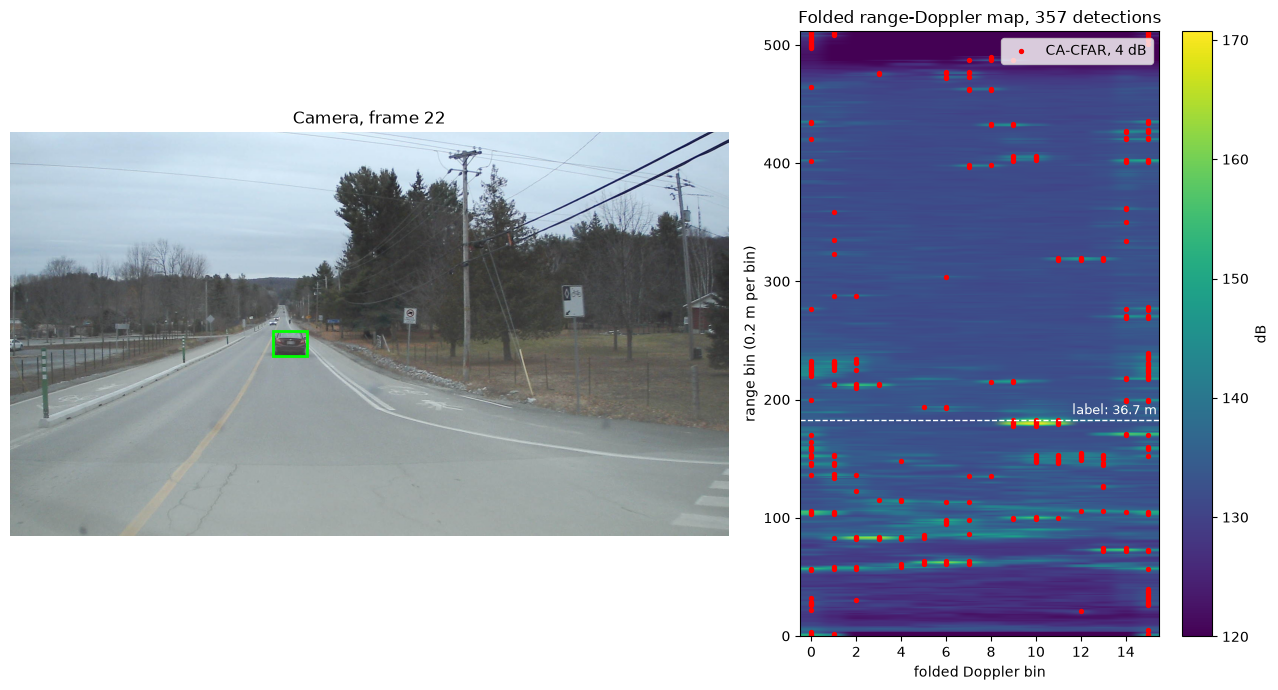

In [45]:
k = 22
P = P_all[k]
hits = ca_cfar(P, thr_db=4)                       # the frozen threshold
det = np.argwhere(hits)
fk = lab[lab["index"] == k]
img = read_image(camera_for(frames[k]))

fig, ax = plt.subplots(1, 2, figsize=(13, 7), gridspec_kw={"width_ratios": [1.6, 1]})

ax[0].imshow(img[:, :, ::-1]); ax[0].axis("off")
ax[0].set_title(f"Camera, frame {k}")

im = ax[1].imshow(20*np.log10(P + 1e-9), aspect="auto", origin="lower", vmin=120)
ax[1].scatter(det[:, 1], det[:, 0], s=8, c="r", label="CA-CFAR, 4 dB")
for rb, r in zip(fk["range_bin"], fk["radar_R_m"]):
    ax[1].axhline(rb, color="w", ls="--", lw=1)
    ax[1].text(15.4, rb + 5, f"label: {r:.1f} m", color="w", ha="right", fontsize=9)
ax[1].set_xlabel("folded Doppler bin")
ax[1].set_ylabel("range bin (0.2 m per bin)")
ax[1].set_title(f"Folded range-Doppler map, {hits.sum()} detections")
ax[1].legend(loc="upper right")
fig.colorbar(im, ax=ax[1], label="dB")

for _, r in fk.iterrows():
    ax[0].add_patch(plt.Rectangle((r["x1_pix"], r["y1_pix"]), r["x2_pix"] - r["x1_pix"], r["y2_pix"] - r["y1_pix"], fill=False, ec="lime", lw=2))

plt.tight_layout()
plt.savefig("../figures/fig1_camera_rd_cfar.png", dpi=150, bbox_inches="tight")
plt.show()

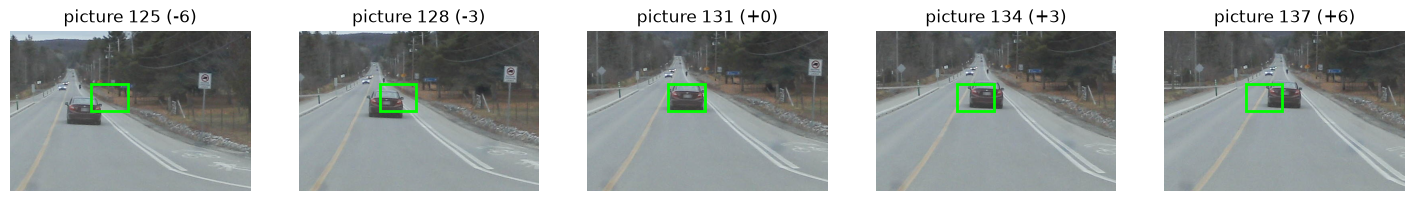

In [46]:
j0 = camera_for(frames[22])
fig, ax = plt.subplots(1, 5, figsize=(18, 4))

for a, dj in zip(ax, (-6, -3, 0, 3, 6)):
    crop = read_image(j0 + dj)[400:800, 500:1100, ::-1]       # the region around the car, RGB
    a.imshow(crop); a.axis("off"); a.set_title(f"picture {j0+dj} ({dj:+d})")
    for _, r in fk.iterrows():
        a.add_patch(plt.Rectangle((r["x1_pix"] - 500, r["y1_pix"] - 400),
                                  r["x2_pix"] - r["x1_pix"], r["y2_pix"] - r["y1_pix"],
                                  fill=False, ec="lime", lw=2))
plt.show()

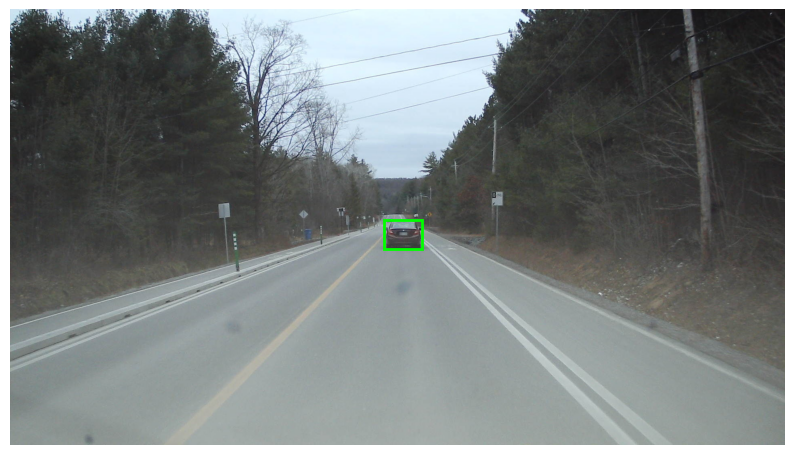

In [50]:
k = ks[200]                                    # another labelled frame
fk = lab[lab["index"] == k]
img = read_image(camera_for(frames[k]))
plt.figure(figsize=(10, 6)); plt.imshow(img[:, :, ::-1]); plt.axis("off")
for _, r in fk.iterrows():
    plt.gca().add_patch(plt.Rectangle((r["x1_pix"], r["y1_pix"]), r["x2_pix"] - r["x1_pix"], r["y2_pix"] - r["y1_pix"], fill=False, ec="lime", lw=2))
plt.show()